In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os
import numpy as np

In [7]:
import math

### Build de EDA functions

In [2]:
def build_master_dataframe(directory_path):
    start_time = time.time()
    master_rows = []

    for filename in os.listdir(directory_path):
        if filename.endswith(".parquet"):
            file_path = os.path.join(directory_path, filename)
            df = pd.read_parquet(file_path)

            country_name = filename.split("_")[0]
            df = df[df["Year"] >= 2015].copy()
            df = df.ffill().bfill()

            # Eliminar columna 'house_price' si existe
            if "house_price" in df.columns:
                df.drop(columns=["house_price"], inplace=True)

            country_features = {"Country": country_name}
            macro_columns = [col for col in df.columns if col != "Year"]

            for col in macro_columns:
                series = df[col].values
                years = df["Year"].values.reshape(-1, 1)

                country_features[f"{col}_mean"] = np.mean(series)
                country_features[f"{col}_median"] = np.median(series)
                country_features[f"{col}_std"] = np.std(series)
                country_features[f"{col}_cv"] = np.std(series) / np.mean(series) if np.mean(series) != 0 else 0
                country_features[f"{col}_min"] = np.min(series)
                country_features[f"{col}_max"] = np.max(series)
                country_features[f"{col}_last"] = series[-1]
                country_features[f"{col}_growth"] = (series[-1] - series[0]) / series[0] if series[0] != 0 else 0

                if np.std(series) < 1e-8:
                    country_features[f"{col}_skew"] = 0
                    country_features[f"{col}_kurtosis"] = 0
                else:
                    country_features[f"{col}_skew"] = skew(series)
                    country_features[f"{col}_kurtosis"] = kurtosis(series)

                try:
                    model = LinearRegression().fit(years, series)
                    country_features[f"{col}_trend"] = model.coef_[0]
                except:
                    country_features[f"{col}_trend"] = np.nan

            master_rows.append(country_features)

    master_df = pd.DataFrame(master_rows)
    end_time = time.time()
    print(f"Time taken to perform feature engineering: {round(end_time - start_time, 2)} sec.")
    return master_df

In [3]:
def detect_outlier_columns(directory_path, year_threshold=2015, iqr_multiplier=1.5):
    outlier_report = {}

    for filename in os.listdir(directory_path):
        if filename.endswith(".parquet"):
            file_path = os.path.join(directory_path, filename)
            df = pd.read_parquet(file_path)

            country_name = filename.split("_")[0]
            df = df[df["Year"] >= year_threshold].copy()
            df = df.ffill().bfill()

            if "house_price" in df.columns:
                df.drop(columns=["house_price"], inplace=True)

            macro_columns = [col for col in df.columns if col != "Year"]
            outlier_cols = []

            for col in macro_columns:
                series = df[col].dropna()
                if len(series) < 5:
                    continue  # Evita columnas con pocos datos

                q1 = np.percentile(series, 25)
                q3 = np.percentile(series, 75)
                iqr = q3 - q1
                lower_bound = q1 - iqr_multiplier * iqr
                upper_bound = q3 + iqr_multiplier * iqr

                outliers = series[(series < lower_bound) | (series > upper_bound)]
                if len(outliers) > 0:
                    outlier_cols.append(col)

            outlier_report[country_name] = outlier_cols

    return outlier_report

In [4]:
detect_outlier_columns('../data/by_country/')

{'Australia': ['agr_land', 'inflation_df', 'govermment_effective_df'],
 'Austria': ['rule_of_law_df',
  'share_of_industry_df',
  'inflation_df',
  'govermment_effective_df'],
 'Belgium': ['agr_land',
  'share_of_industry_df',
  'tax_revenue_df',
  'inflation_df',
  'edu_spending_df'],
 'Brazil': ['inflation_df'],
 'Bulgaria': ['inflation_df'],
 'Canada': ['agr_land', 'unemployment', 'inflation_df'],
 'Chile': ['livestock_prod', 'inflation_df'],
 'Colombia': ['livestock_prod',
  'unemployment',
  'inflation_df',
  'edu_spending_df'],
 'Croatia': ['gov_exp',
  'reserves',
  'share_of_industry_df',
  'inflation_df',
  'edu_spending_df'],
 'Cyprus': ['agr_land', 'inflation_df'],
 'Czech': ['livestock_prod',
  'agr_land',
  'reserves',
  'unemployment',
  'inflation_df',
  'edu_spending_df'],
 'Denmark': ['livestock_prod', 'share_of_industry_df', 'inflation_df'],
 'Estonia': ['livestock_prod', 'agr_land', 'inflation_df', 'edu_spending_df'],
 'Finland': ['share_of_industry_df',
  'tax_reven

In [8]:
def plot_boxplot_grid_from_parquet(file_path, columns_to_plot, year_threshold=2015, cols_per_row=3):
    # Cargar y preparar el DataFrame
    df = pd.read_parquet(file_path)
    if "Year" in df.columns:
        df = df[df["Year"] >= year_threshold].copy()
    df = df.ffill().bfill()

    # Filtrar columnas válidas
    valid_columns = [col for col in columns_to_plot if col in df.columns and pd.api.types.is_numeric_dtype(df[col])]
    if not valid_columns:
        print("No hay columnas válidas para graficar.")
        return

    # Calcular disposición del grid
    total_plots = len(valid_columns)
    rows = math.ceil(total_plots / cols_per_row)

    # Crear figura
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(cols_per_row * 4, rows * 4))
    axes = axes.flatten()  # Aplanar para indexar fácilmente

    for i, col in enumerate(valid_columns):
        axes[i].boxplot(df[col].dropna())
        axes[i].set_title(col)
        axes[i].tick_params(axis='x', labelrotation=45)

    # Ocultar ejes vacíos si sobran
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.suptitle("Boxplots por variable", fontsize=16, y=1.02)
    plt.show()


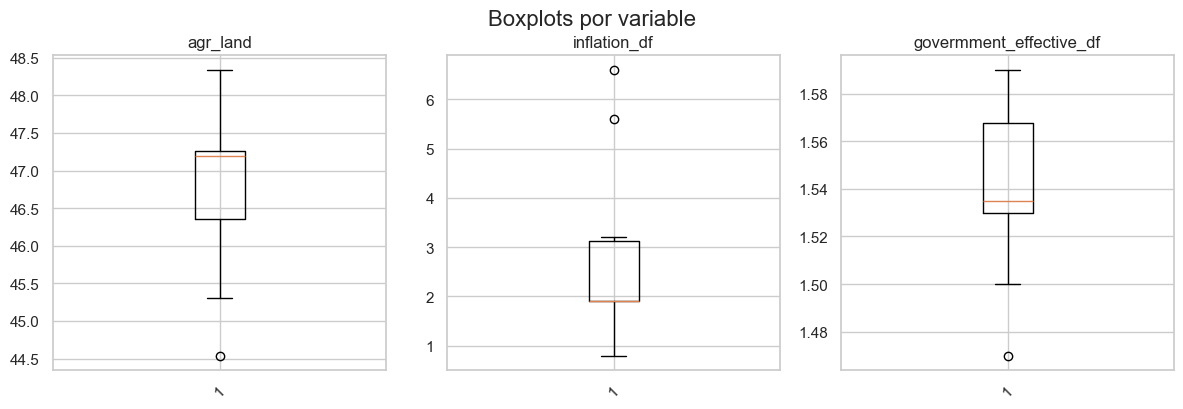

In [9]:
plot_boxplot_grid_from_parquet('../data/by_country/Australia_macro_profile.parquet', ['agr_land', 'inflation_df', 'govermment_effective_df'])

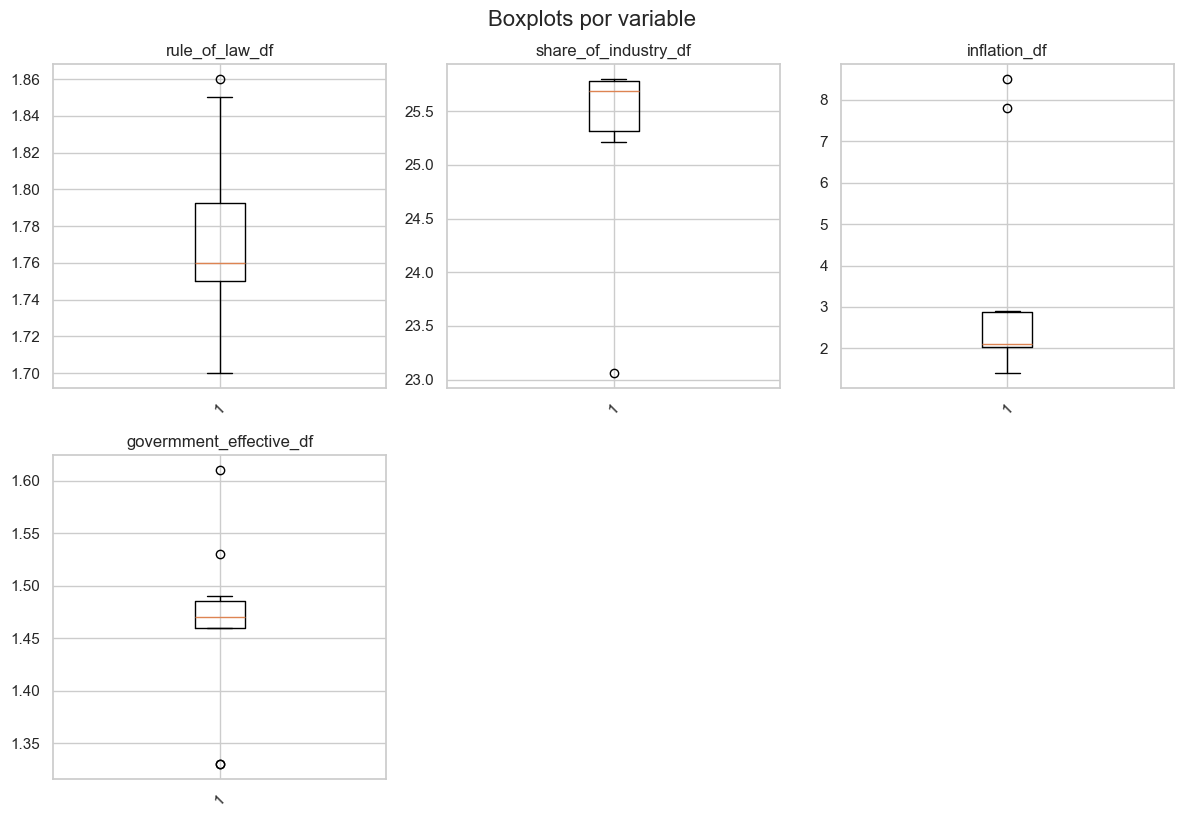

In [10]:
plot_boxplot_grid_from_parquet('../data/by_country/Austria_macro_profile.parquet', 
                               ['rule_of_law_df',
                                'share_of_industry_df',
                                'inflation_df',
                                'govermment_effective_df'])

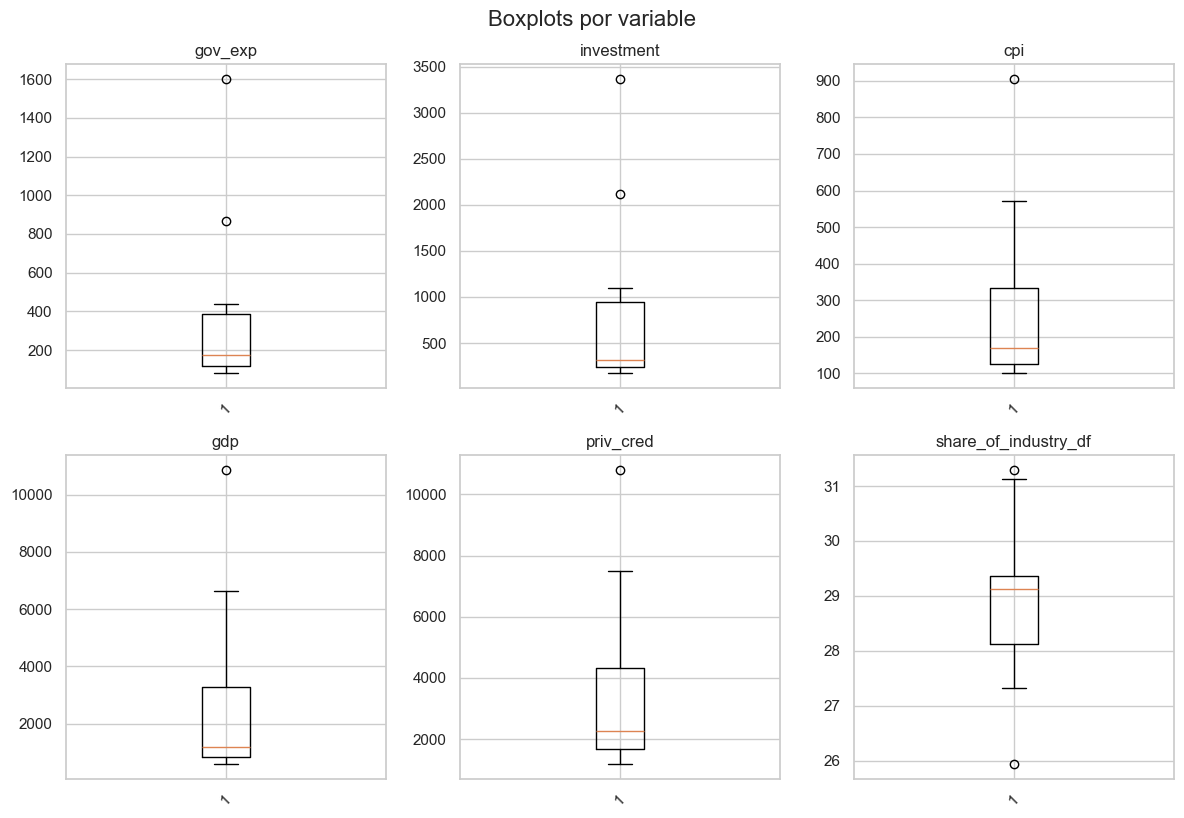

In [11]:
plot_boxplot_grid_from_parquet('../data/by_country/Turkey_macro_profile.parquet', 
                               ['gov_exp',
                                'investment',
                                'cpi',
                                'gdp',
                                'priv_cred',
                                'share_of_industry_df'])

### Work over outliers before summarize in one point the countries

In [18]:
from collections import Counter

In [16]:
def check_remaining_outliers(dataframes_dict, iqr_multiplier=1.5):
    outlier_check_report = {}

    for country, df in dataframes_dict.items():
        outlier_columns = []

        macro_columns = [col for col in df.columns if col != "Year" and pd.api.types.is_numeric_dtype(df[col])]
        for col in macro_columns:
            series = df[col].dropna()
            if len(series) < 5:
                continue  # Evita columnas con pocos datos

            q1 = np.percentile(series, 25)
            q3 = np.percentile(series, 75)
            iqr = q3 - q1
            lower_bound = q1 - iqr_multiplier * iqr
            upper_bound = q3 + iqr_multiplier * iqr

            outliers = series[(series < lower_bound) | (series > upper_bound)]
            if len(outliers) > 0:
                outlier_columns.append(col)

        if outlier_columns:
            outlier_check_report[country] = outlier_columns

    return outlier_check_report

In [44]:
def rank_outlier_variables(outlier_dict, exclude_columns={"Year"}):
    counter = Counter()
    for macro_list in outlier_dict.values():
        filtered_macros = [col for col in macro_list if col not in exclude_columns]
        counter.update(filtered_macros)

    sorted_macros = sorted(counter.items(), key=lambda x: x[1], reverse=True)

    print("📊 Ranking de macroeconómicos con outliers (por número de países):\n")
    for macro, count in sorted_macros:
        print(f"{macro}: {count} países")

In [67]:
def adaptive_winsorize(series, iqr_multiplier=2.0):
    q1 = np.percentile(series, 25)
    q3 = np.percentile(series, 75)
    iqr = q3 - q1
    lower = q1 - iqr_multiplier * iqr
    upper = q3 + iqr_multiplier * iqr
    return np.clip(series, lower, upper)

def preprocess_parquets_with_log_and_winsorization(directory_path, year_threshold=2015):
    # Variables recomendadas para log transform
    log_variables = {
        "inflation_df",
        "edu_spending_df",
        "livestock_prod",
        "tax_revenue_df",
        "reserves",
        "labor_force",
        "priv_cred",
        "cpi",
        "gov_exp",
        "investment",
        "gdp"
    }

    processed_dataframes = {}

    for filename in os.listdir(directory_path):
        if filename.endswith(".parquet"):
            file_path = os.path.join(directory_path, filename)
            df = pd.read_parquet(file_path)

            # Filtrar años y rellenar vacíos
            if "Year" in df.columns:
                df = df[df["Year"] >= year_threshold].copy()
            df = df.ffill().bfill()

            # Aplicar log transform solo a variables recomendadas
            for col in df.columns:
                if col in log_variables and pd.api.types.is_numeric_dtype(df[col]):
                    df[col] = df[col].apply(lambda x: np.nan if x <= 0 else np.log1p(x))

            # Aplicar winsorización adaptativa a todas las columnas numéricas
            for col in df.columns:
                if col != "Year" and pd.api.types.is_numeric_dtype(df[col]):
                    df[col] = adaptive_winsorize(df[col])

            # Extraer nombre del país desde el nombre del archivo
            country_name = country_name = filename.replace("_macro_profile.parquet", "")
            processed_dataframes[country_name] = df

    return processed_dataframes

In [68]:
processed_dataframes = preprocess_parquets_with_log_and_winsorization('../data/by_country/')

In [69]:
rank_outlier_variables(processed_dataframes)

📊 Ranking de macroeconómicos con outliers (por número de países):

labor_force: 53 países
livestock_prod: 53 países
agr_land: 53 países
urban_pop: 53 países
gov_exp: 53 países
reserves: 53 países
investment: 53 países
cpi: 53 países
gdp: 53 países
priv_cred: 53 países
unemployment: 53 países
house_price: 53 países
rule_of_law_df: 53 países
share_of_industry_df: 53 países
tax_revenue_df: 53 países
inflation_df: 53 países
edu_spending_df: 53 países
govermment_effective_df: 53 países


In [70]:
check_remaining_outliers(processed_dataframes)

{'Australia': ['agr_land', 'inflation_df', 'govermment_effective_df'],
 'Austria': ['rule_of_law_df',
  'share_of_industry_df',
  'inflation_df',
  'govermment_effective_df'],
 'Belgium': ['agr_land',
  'share_of_industry_df',
  'tax_revenue_df',
  'inflation_df',
  'edu_spending_df'],
 'Brazil': ['inflation_df'],
 'Bulgaria': ['inflation_df'],
 'Canada': ['agr_land', 'unemployment'],
 'Chile': ['livestock_prod', 'inflation_df'],
 'Colombia': ['livestock_prod', 'unemployment', 'edu_spending_df'],
 'Croatia': ['reserves',
  'share_of_industry_df',
  'inflation_df',
  'edu_spending_df'],
 'Cyprus': ['agr_land', 'house_price'],
 'Czech_Republic': ['livestock_prod',
  'agr_land',
  'reserves',
  'unemployment',
  'inflation_df',
  'edu_spending_df'],
 'Denmark': ['livestock_prod', 'share_of_industry_df', 'inflation_df'],
 'Estonia': ['livestock_prod', 'agr_land', 'inflation_df', 'edu_spending_df'],
 'Finland': ['investment',
  'house_price',
  'share_of_industry_df',
  'tax_revenue_df',
  

In [71]:
processed_dataframes['New_Zealand']

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
8,2015,1.294727,4.631812,40.68,86.40,2.442130,3.243178,2.708550,6.886717,4.141347,6.286018,4.425000,137.1775,1.91,20.17,3.346037,0.955511,1.903599,1.81
9,2016,1.294727,4.612146,40.31,86.40,2.546707,3.260977,2.804118,6.893152,4.206966,6.261019,4.425000,156.6250,1.91,20.17,3.341093,0.955511,1.873339,1.81
10,2017,1.321756,4.602166,40.42,86.47,2.619583,3.364994,2.860485,6.911472,4.270257,5.999069,4.283333,166.8025,1.88,20.53,3.343215,0.955511,1.837370,1.73
11,2018,1.335001,4.631812,39.87,86.54,2.679651,3.413428,2.912622,6.927313,4.318621,6.050731,4.141667,172.7950,1.83,20.38,3.348500,0.955511,1.822935,1.63
12,2019,1.345472,4.630838,39.29,86.61,2.760643,3.373198,2.990468,6.943364,4.385676,6.105018,4.100000,178.1925,1.84,20.37,3.372455,0.955511,1.821318,1.63
13,2020,1.360977,4.638605,38.56,86.70,2.852872,3.353960,2.932526,6.960348,4.404919,6.143730,4.250000,196.3125,1.84,19.98,3.343921,0.993252,1.894617,1.54
14,2021,1.371181,4.639572,38.64,86.79,2.963467,3.072886,3.106155,6.998966,4.487681,6.197925,3.975000,248.2650,1.78,18.83,3.401864,1.589235,1.879465,1.31
15,2022,1.378766,4.605170,37.02,86.80,3.057533,3.088957,3.229717,7.068172,4.566871,6.253822,3.808333,249.6925,1.73,19.60,3.421000,2.104134,1.829376,1.34
16,2023,1.403643,4.605170,37.02,86.90,3.129061,3.304227,3.284195,7.123874,4.640899,6.282971,3.966667,233.5425,1.71,19.60,3.421000,1.902108,1.829376,1.53
17,2024,1.403643,4.605170,37.02,86.90,3.177533,3.528515,3.263945,7.152660,4.678792,6.309480,3.966667,233.6800,1.71,19.60,3.421000,1.360977,1.829376,1.53


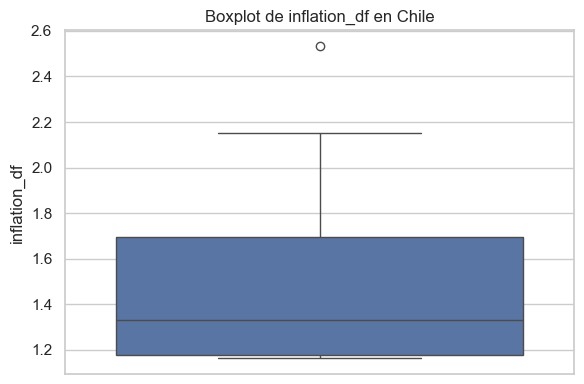

In [72]:
# Seleccionar el DataFrame del país
df_chile = processed_dataframes["Chile"]

# Seleccionar la variable macroeconómica
macro = "inflation_df"

# Crear el boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(y=df_chile[macro])
plt.title(f"Boxplot de {macro} en Chile")
plt.ylabel(macro)
plt.tight_layout()
plt.show()

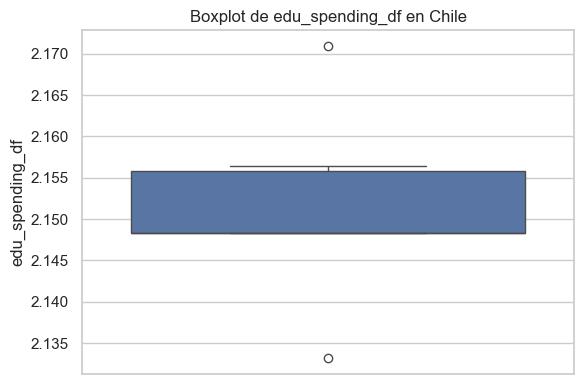

In [73]:
# Seleccionar el DataFrame del país
df_chile = processed_dataframes["Sweden"]

# Seleccionar la variable macroeconómica
macro = "edu_spending_df"

# Crear el boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(y=df_chile[macro])
plt.title(f"Boxplot de {macro} en Chile")
plt.ylabel(macro)
plt.tight_layout()
plt.show()

### Convert in one point data the countries

In [54]:
import time
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression

In [74]:
def build_master_dataframe_from_dict(dataframes_dict):
    start_time = time.time()
    master_rows = []

    for country_name, df in dataframes_dict.items():
        df = df[df["Year"] >= 2015].copy()
        df = df.ffill().bfill()

        # Eliminar columna 'house_price' si existe
        if "house_price" in df.columns:
            df.drop(columns=["house_price"], inplace=True)

        country_features = {"Country": country_name}
        macro_columns = [col for col in df.columns if col != "Year"]

        for col in macro_columns:
            series = df[col].values
            years = df["Year"].values.reshape(-1, 1)

            country_features[f"{col}_mean"] = np.mean(series)
            country_features[f"{col}_median"] = np.median(series)
            country_features[f"{col}_std"] = np.std(series)
            country_features[f"{col}_cv"] = np.std(series) / np.mean(series) if np.mean(series) != 0 else 0
            country_features[f"{col}_min"] = np.min(series)
            country_features[f"{col}_max"] = np.max(series)
            country_features[f"{col}_last"] = series[-1]
            country_features[f"{col}_growth"] = (series[-1] - series[0]) / series[0] if series[0] != 0 else 0

            if np.std(series) < 1e-8:
                country_features[f"{col}_skew"] = 0
                country_features[f"{col}_kurtosis"] = 0
            else:
                country_features[f"{col}_skew"] = skew(series)
                country_features[f"{col}_kurtosis"] = kurtosis(series)

            try:
                model = LinearRegression().fit(years, series)
                country_features[f"{col}_trend"] = model.coef_[0]
            except:
                country_features[f"{col}_trend"] = np.nan

        master_rows.append(country_features)

    master_df = pd.DataFrame(master_rows)
    end_time = time.time()
    print(f"Time taken to perform feature engineering: {round(end_time - start_time, 2)} sec.")
    return master_df

In [81]:
master_df = build_master_dataframe_from_dict(processed_dataframes)

Time taken to perform feature engineering: 1.34 sec.


In [82]:
master_df

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,2.678890,2.679994,0.042374,0.015818,2.619583,2.740840,2.740840,0.046289,0.046350,...,1.535,0.036180,2.347833e-02,1.4700,1.590,1.590,0.039216,-0.346877,-0.627720,0.005273
1,Austria,1.736643,1.731654,0.016233,0.009347,1.717395,1.763017,1.763017,0.026565,0.515156,...,1.470,0.039525,2.687882e-02,1.4100,1.535,1.410,-0.040816,0.066706,-0.672530,-0.004576
2,Belgium,1.825060,1.821317,0.024303,0.013317,1.791759,1.859418,1.859418,0.037761,0.121315,...,1.165,0.129016,1.088738e-01,1.0400,1.400,1.040,-0.257143,0.542175,-1.048411,-0.037758
3,Brazil,4.651135,4.653483,0.021975,0.004725,4.612046,4.675629,4.673763,0.010121,-0.392741,...,-0.480,0.135632,-3.214025e-01,-0.5900,-0.230,-0.550,1.200000,0.321185,-1.620024,-0.038182
4,Bulgaria,1.447840,1.451614,0.022617,0.015621,1.408545,1.477049,1.408545,-0.029670,-0.654102,...,0.070,0.146969,-5.295130e+16,-0.2700,0.170,0.050,-0.444444,-0.794950,-1.012397,-0.022303
5,Canada,3.081890,3.073828,0.036273,0.011770,3.038792,3.141563,3.141563,0.033820,0.510275,...,1.640,0.099524,6.050083e-02,1.5200,1.820,1.520,-0.126437,0.228245,-1.279805,-0.031697
6,Chile,2.327667,2.318950,0.041785,0.017951,2.278292,2.394252,2.394252,0.050898,0.479126,...,0.765,0.110910,1.472907e-01,0.5500,0.910,0.720,-0.132530,-0.487748,-0.865772,-0.025273
7,Colombia,3.263395,3.260973,0.032584,0.009985,3.217675,3.306520,3.306520,0.027612,-0.051684,...,-0.110,0.064969,-7.827617e-01,-0.1400,0.010,-0.080,-0.428571,0.542294,-1.444192,0.014000
8,Croatia,1.010808,1.007958,0.011442,0.011320,0.996949,1.029619,1.007958,-0.021038,0.652768,...,0.525,0.104575,1.965702e-01,0.4200,0.710,0.710,0.690476,0.594399,-0.899318,0.029818
9,Cyprus,0.523890,0.521761,0.022211,0.042397,0.494696,0.553885,0.553885,0.119647,0.060286,...,0.860,0.092758,1.112203e-01,0.7000,0.960,0.740,-0.204301,-0.143984,-1.606241,-0.027273


### Because the presence of outliers continue use robust scaler

In [77]:
from sklearn.preprocessing import RobustScaler

In [83]:
def scale_master_dataframe_robust(master_df):
    # Separar columna de país
    country_column = master_df["Country"]
    
    # Seleccionar solo columnas numéricas
    numeric_df = master_df.drop(columns=["Country"])
    
    # Aplicar RobustScaler
    scaler = RobustScaler()
    scaled_array = scaler.fit_transform(numeric_df)
    
    # Reconstruir DataFrame escalado
    scaled_df = pd.DataFrame(scaled_array, columns=numeric_df.columns)
    scaled_df.insert(0, "Country", country_column.values)
    
    return scaled_df

In [84]:
scaled_master_df = scale_master_dataframe_robust(master_df)

In [85]:
scaled_master_df

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.202714,0.192674,0.929680,0.455345,0.196401,0.214118,0.248345,0.595002,-0.164568,...,0.422131,-1.092997,-4.695869e-01,0.470588,0.438596,0.444444,0.205169,-0.530109,1.086080,0.359290
1,Austria,-0.263867,-0.280144,-0.242138,-0.199662,-0.244957,-0.270228,-0.225042,0.000000,0.421480,...,0.368852,-1.036062,-4.372766e-01,0.420168,0.390351,0.311111,0.012190,0.243008,1.005727,0.137295
2,Belgium,-0.220085,-0.235440,0.119635,0.202138,-0.208577,-0.222477,-0.178372,0.337755,-0.070855,...,0.118852,0.487044,3.418103e-01,0.109244,0.271930,0.037037,-0.509433,1.131808,0.331708,-0.610656
3,Brazil,1.179330,1.176606,0.015253,-0.667595,1.171130,1.172479,1.184118,-0.496031,-0.713469,...,-1.229508,0.599653,-3.746519e+00,-1.260504,-1.157895,-1.140741,3.004137,0.718709,-0.693295,-0.620219
4,Bulgaria,-0.406877,-0.419765,0.044058,0.435465,-0.396049,-0.411877,-0.396650,-1.696386,-1.040194,...,-0.778689,0.792616,-5.031240e+17,-0.991597,-0.807018,-0.696296,-0.961068,-1.367699,0.396286,-0.262295
5,Canada,0.402271,0.389030,0.656161,0.045547,0.401481,0.412608,0.442344,0.218859,0.415380,...,0.508197,-0.014898,-1.178125e-01,0.512605,0.640351,0.392593,-0.194265,0.544974,-0.083223,-0.474044
6,Chile,0.028795,0.012667,0.903258,0.671318,0.029439,0.042442,0.080554,0.734042,0.376440,...,-0.209016,0.178890,7.068331e-01,-0.302521,-0.157895,-0.200000,-0.208957,-0.793442,0.659211,-0.329235
7,Colombia,0.492149,0.482336,0.490817,-0.135134,0.488992,0.494317,0.522204,0.031584,-0.287119,...,-0.926230,-0.603012,-8.130187e+00,-0.882353,-0.947368,-0.792593,-0.922794,1.132031,-0.377998,0.556011
8,Croatia,-0.623286,-0.640961,-0.456890,0.000000,-0.597405,-0.633502,-0.590584,-1.436011,0.593508,...,-0.405738,0.071077,1.175069e+00,-0.411765,-0.333333,-0.207407,1.775536,1.229432,0.599056,0.912568
9,Cyprus,-0.864398,-0.883366,0.025852,3.145856,-0.843111,-0.869148,-0.810411,2.807959,-0.147146,...,-0.131148,-0.130056,3.641057e-01,-0.176471,-0.114035,-0.185185,-0.382017,-0.150839,-0.668579,-0.374317


In [111]:
scaled_master_df.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.202714,0.192674,0.929680,0.455345,0.196401,0.214118,0.248345,0.595002,-0.164568,...,0.422131,-1.092997,-4.695869e-01,0.470588,0.438596,0.444444,0.205169,-0.530109,1.086080,0.359290
1,Austria,-0.263867,-0.280144,-0.242138,-0.199662,-0.244957,-0.270228,-0.225042,0.000000,0.421480,...,0.368852,-1.036062,-4.372766e-01,0.420168,0.390351,0.311111,0.012190,0.243008,1.005727,0.137295
2,Belgium,-0.220085,-0.235440,0.119635,0.202138,-0.208577,-0.222477,-0.178372,0.337755,-0.070855,...,0.118852,0.487044,3.418103e-01,0.109244,0.271930,0.037037,-0.509433,1.131808,0.331708,-0.610656
3,Brazil,1.179330,1.176606,0.015253,-0.667595,1.171130,1.172479,1.184118,-0.496031,-0.713469,...,-1.229508,0.599653,-3.746519e+00,-1.260504,-1.157895,-1.140741,3.004137,0.718709,-0.693295,-0.620219
4,Bulgaria,-0.406877,-0.419765,0.044058,0.435465,-0.396049,-0.411877,-0.396650,-1.696386,-1.040194,...,-0.778689,0.792616,-5.031240e+17,-0.991597,-0.807018,-0.696296,-0.961068,-1.367699,0.396286,-0.262295


In [116]:
scaled_master_df.to_parquet('../data/log_win_transform_then_one_point_countries_robus_scaler_ready_for_clust_and_pca.parquet')

### Obtain the countries that explain the 80% of the outliers

In [113]:
def rank_countries_by_outliers(master_df, exclude_columns={"Country"}, iqr_multiplier=1.5):
    outlier_counts = []

    # Seleccionar solo columnas numéricas
    numeric_columns = [col for col in master_df.columns if col not in exclude_columns]

    # Calcular IQR por columna
    q1 = master_df[numeric_columns].quantile(0.25)
    q3 = master_df[numeric_columns].quantile(0.75)
    iqr = q3 - q1
    lower_bounds = q1 - iqr_multiplier * iqr
    upper_bounds = q3 + iqr_multiplier * iqr

    # Iterar por país
    for idx, row in master_df.iterrows():
        country = row["Country"]
        outlier_cols = []

        for col in numeric_columns:
            val = row[col]
            if pd.notnull(val):
                if val < lower_bounds[col] or val > upper_bounds[col]:
                    outlier_cols.append(col)

        outlier_counts.append({
            "Country": country,
            "Outlier_Count": len(outlier_cols),
            "Outlier_Columns": outlier_cols
        })

    # Convertir a DataFrame ordenado
    outlier_df = pd.DataFrame(outlier_counts)
    outlier_df.sort_values(by="Outlier_Count", ascending=False, inplace=True)
    outlier_df.reset_index(drop=True, inplace=True)
    return outlier_df

In [114]:
countries_outilers = rank_countries_by_outliers(scaled_master_df)

In [115]:
countries_outilers

,Country,Outlier_Count,Outlier_Columns
0,Turkey,48,"[livestock_prod_mean, livestock_prod_median, l..."
1,South_Korea,28,"[agr_land_growth, urban_pop_skew, urban_pop_ku..."
2,India,28,"[livestock_prod_mean, livestock_prod_median, l..."
3,Colombia,21,"[livestock_prod_min, livestock_prod_kurtosis, ..."
4,Greece,17,"[agr_land_std, agr_land_growth, agr_land_trend..."
5,Cyprus,16,"[labor_force_cv, labor_force_growth, urban_pop..."
6,Norway,15,"[share_of_industry_df_std, share_of_industry_d..."
7,Thailand,15,"[urban_pop_std, urban_pop_cv, urban_pop_growth..."
8,Lithuania,14,"[labor_force_kurtosis, gov_exp_growth, reserve..."
9,Malta,14,"[agr_land_std, agr_land_cv, agr_land_growth, a..."


In [101]:
def apply_pareto_rule_to_outliers(outlier_df, threshold=0.8):
    """
    Applies the Pareto 80/20 rule to identify the smallest set of countries
    responsible for at least 'threshold' proportion of total outliers.

    Parameters:
    - outlier_df: DataFrame with columns 'Country' and 'Outlier_Count'
    - threshold: float, default 0.8 (80%)

    Returns:
    - DataFrame of top countries contributing to the majority of outliers
    """

    sorted_df = outlier_df.sort_values(by="Outlier_Count", ascending=False).reset_index(drop=True)
    total_outliers = sorted_df["Outlier_Count"].sum()

    sorted_df["Cumulative_Outliers"] = sorted_df["Outlier_Count"].cumsum()
    sorted_df["Cumulative_%"] = sorted_df["Cumulative_Outliers"] / total_outliers

    pareto_df = sorted_df[sorted_df["Cumulative_%"] <= threshold].copy()

    if not pareto_df.empty and pareto_df["Cumulative_%"].iloc[-1] < threshold:
        next_row = sorted_df.iloc[len(pareto_df)]
        pareto_df = pd.concat([pareto_df, next_row.to_frame().T], ignore_index=True)

    # Fix: Ensure numeric before rounding
    pareto_df["Cumulative_%"] = pd.to_numeric(pareto_df["Cumulative_%"], errors="coerce") * 100
    pareto_df["Cumulative_%"] = pareto_df["Cumulative_%"].round(2)

    return pareto_df

In [102]:
pareto_countries_outliers = apply_pareto_rule_to_outliers(countries_outilers)

In [103]:
pareto_countries_outliers

,Country,Outlier_Count,Outlier_Columns,Cumulative_Outliers,Cumulative_%
0,Turkey,48,"[livestock_prod_mean, livestock_prod_median, l...",48,10.84
1,South_Korea,28,"[agr_land_growth, urban_pop_skew, urban_pop_ku...",76,17.16
2,India,28,"[livestock_prod_mean, livestock_prod_median, l...",104,23.48
3,Colombia,21,"[livestock_prod_min, livestock_prod_kurtosis, ...",125,28.22
4,Greece,17,"[agr_land_std, agr_land_growth, agr_land_trend...",142,32.05
5,Cyprus,16,"[labor_force_cv, labor_force_growth, urban_pop...",158,35.67
6,Norway,15,"[share_of_industry_df_std, share_of_industry_d...",173,39.05
7,Thailand,15,"[urban_pop_std, urban_pop_cv, urban_pop_growth...",188,42.44
8,Lithuania,14,"[labor_force_kurtosis, gov_exp_growth, reserve...",202,45.60
9,Malta,14,"[agr_land_std, agr_land_cv, agr_land_growth, a...",216,48.76


### Remove certain threshold of the countries that explain the outliers presense

In [106]:
def remove_countries_by_cumulative_threshold(master_df, pareto_df, cumulative_limit=50):
    """
    Removes countries from master_df whose cumulative outlier contribution
    (from the Pareto subset) is less than or equal to the specified percentage.

    Parameters:
    - master_df: Full DataFrame of countries and macroeconomic features
    - pareto_df: DataFrame returned by apply_pareto_rule_to_outliers
    - cumulative_limit: int or float, max cumulative percentage to filter (e.g. 50)

    Returns:
    - Filtered master_df with selected countries removed
    """

    # Ensure cumulative percentage is numeric
    pareto_df["Cumulative_%"] = pd.to_numeric(pareto_df["Cumulative_%"], errors="coerce")

    # Select countries within the cumulative threshold
    countries_to_remove = pareto_df[pareto_df["Cumulative_%"] <= cumulative_limit]["Country"].tolist()

    # Filter master_df
    filtered_df = master_df[~master_df["Country"].isin(countries_to_remove)].reset_index(drop=True)

    return filtered_df

In [107]:
without_80percent_countries_outliers = remove_countries_by_cumulative_threshold(scaled_master_df, pareto_countries_outliers, cumulative_limit=80)

In [108]:
rank_countries_by_outliers(without_80percent_countries_outliers)

,Country,Outlier_Count,Outlier_Columns
0,Paraguay,24,"[gov_exp_mean, gov_exp_median, gov_exp_min, in..."
1,Bulgaria,18,"[livestock_prod_median, livestock_prod_min, li..."
2,Luxembourg,16,"[labor_force_cv, labor_force_growth, livestock..."
3,Hungary,12,"[agr_land_std, agr_land_trend, investment_mean..."
4,Israel,12,"[gov_exp_skew, gov_exp_kurtosis, cpi_mean, cpi..."
5,Latvia,12,"[agr_land_growth, gov_exp_cv, gov_exp_growth, ..."
6,Malaysia,12,"[cpi_median, cpi_min, cpi_skew, rule_of_law_df..."
7,Philippines,11,"[livestock_prod_min, gov_exp_skew, cpi_median,..."
8,Spain,10,"[livestock_prod_median, livestock_prod_max, pr..."
9,Mexico,9,"[livestock_prod_max, livestock_prod_last, live..."


In [109]:
without_25percent_countries_outliers = remove_countries_by_cumulative_threshold(scaled_master_df, pareto_countries_outliers, cumulative_limit=25)

In [110]:
rank_countries_by_outliers(without_25percent_countries_outliers)

,Country,Outlier_Count,Outlier_Columns
0,Colombia,24,"[livestock_prod_min, livestock_prod_kurtosis, ..."
1,Cyprus,17,"[labor_force_cv, labor_force_growth, livestock..."
2,Greece,17,"[agr_land_growth, agr_land_trend, reserves_gro..."
3,South_Africa,17,"[agr_land_mean, agr_land_median, agr_land_min,..."
4,Lithuania,15,"[labor_force_kurtosis, gov_exp_cv, gov_exp_gro..."
5,Malta,15,"[agr_land_std, agr_land_cv, agr_land_growth, a..."
6,Japan,15,"[gov_exp_min, investment_mean, investment_medi..."
7,Thailand,15,"[urban_pop_std, urban_pop_cv, urban_pop_growth..."
8,Singapore,14,"[livestock_prod_mean, livestock_prod_median, l..."
9,Norway,14,"[share_of_industry_df_std, share_of_industry_d..."


In [117]:
without_25percent_countries_outliers.to_parquet('../data/log_win_robust_scaler_25_less_outliers_ready_for_clust_and_pca.parquet')

In [118]:
without_80percent_countries_outliers.to_parquet('../data/log_win_robust_scaler_80_less_outliers_ready_for_clust_and_pca.parquet')

### Delete all outliers in one point data countries

In [123]:
from scipy.stats.mstats import winsorize

In [146]:
def adaptive_iterative_winsorize(df, start_limit=0.05, step=0.02, max_limit=0.2):
    """
    Applies winsorization iteratively, increasing the limits step-by-step
    until no outliers remain or max_limit is reached.

    Parameters:
    - df: pandas DataFrame
    - start_limit: initial winsorization limit (e.g. 0.05)
    - step: increment for each iteration (e.g. 0.02)
    - max_limit: maximum winsorization limit allowed (e.g. 0.2)

    Returns:
    - df_cleaned: DataFrame with winsorized values
    - final_limit: the limit at which outliers were eliminated
    - iterations: number of iterations performed
    """
    df_cleaned = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns
    current_limit = start_limit
    iterations = 0

    while current_limit <= max_limit:
        outliers_found = False

        for col in numeric_cols:
            Q1 = df_cleaned[col].quantile(0.25)
            Q3 = df_cleaned[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR

            outliers = df_cleaned[(df_cleaned[col] < lower_bound) | (df_cleaned[col] > upper_bound)]

            if not outliers.empty:
                arr = df_cleaned[col].values
                arr_winsorized = winsorize(arr, limits=(current_limit, current_limit)).data
                df_cleaned[col] = arr_winsorized
                outliers_found = True

        iterations += 1

        if not outliers_found:
            break  # No more outliers detected

        current_limit += step

    return df_cleaned, round(current_limit - step, 3), iterations


In [134]:
def detect_top_outliers(df, top_n=5):
    # Select only numerical columns
    numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

    outlier_counts = {}

    # Count outliers per column using IQR method
    for col in numeric_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
        outlier_counts[col] = outliers.shape[0]

    # Sort columns by number of outliers (descending)
    sorted_outliers = dict(sorted(outlier_counts.items(), key=lambda item: item[1], reverse=True))

    print("Number of outliers per column (sorted):\n")
    for col, count in sorted_outliers.items():
        print(f"{col}: {count}")

    # Plot boxplots for top N columns with most outliers
    top_columns = list(sorted_outliers.keys())[:top_n]

    plt.figure(figsize=(15, top_n * 2))
    for i, col in enumerate(top_columns, 1):
        plt.subplot(top_n, 1, i)
        sns.boxplot(x=df[col], color='salmon')
        plt.title(f'Boxplot of {col}', fontsize=11)
        plt.tight_layout()

    plt.show()

In [147]:
scaled_winsorized, final_limit, n_iters = adaptive_iterative_winsorize(scaled_master_df)
print(f"Final winsorization limit: {final_limit}")
print(f"Iterations performed: {n_iters}")

Final winsorization limit: 0.19
Iterations performed: 8


Number of outliers per column (sorted):

labor_force_mean: 0
labor_force_median: 0
labor_force_std: 0
labor_force_cv: 0
labor_force_min: 0
labor_force_max: 0
labor_force_last: 0
labor_force_growth: 0
labor_force_skew: 0
labor_force_kurtosis: 0
labor_force_trend: 0
livestock_prod_mean: 0
livestock_prod_median: 0
livestock_prod_std: 0
livestock_prod_cv: 0
livestock_prod_min: 0
livestock_prod_max: 0
livestock_prod_last: 0
livestock_prod_growth: 0
livestock_prod_skew: 0
livestock_prod_kurtosis: 0
livestock_prod_trend: 0
agr_land_mean: 0
agr_land_median: 0
agr_land_std: 0
agr_land_cv: 0
agr_land_min: 0
agr_land_max: 0
agr_land_last: 0
agr_land_growth: 0
agr_land_skew: 0
agr_land_kurtosis: 0
agr_land_trend: 0
urban_pop_mean: 0
urban_pop_median: 0
urban_pop_std: 0
urban_pop_cv: 0
urban_pop_min: 0
urban_pop_max: 0
urban_pop_last: 0
urban_pop_growth: 0
urban_pop_skew: 0
urban_pop_kurtosis: 0
urban_pop_trend: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_min: 0
gov_exp

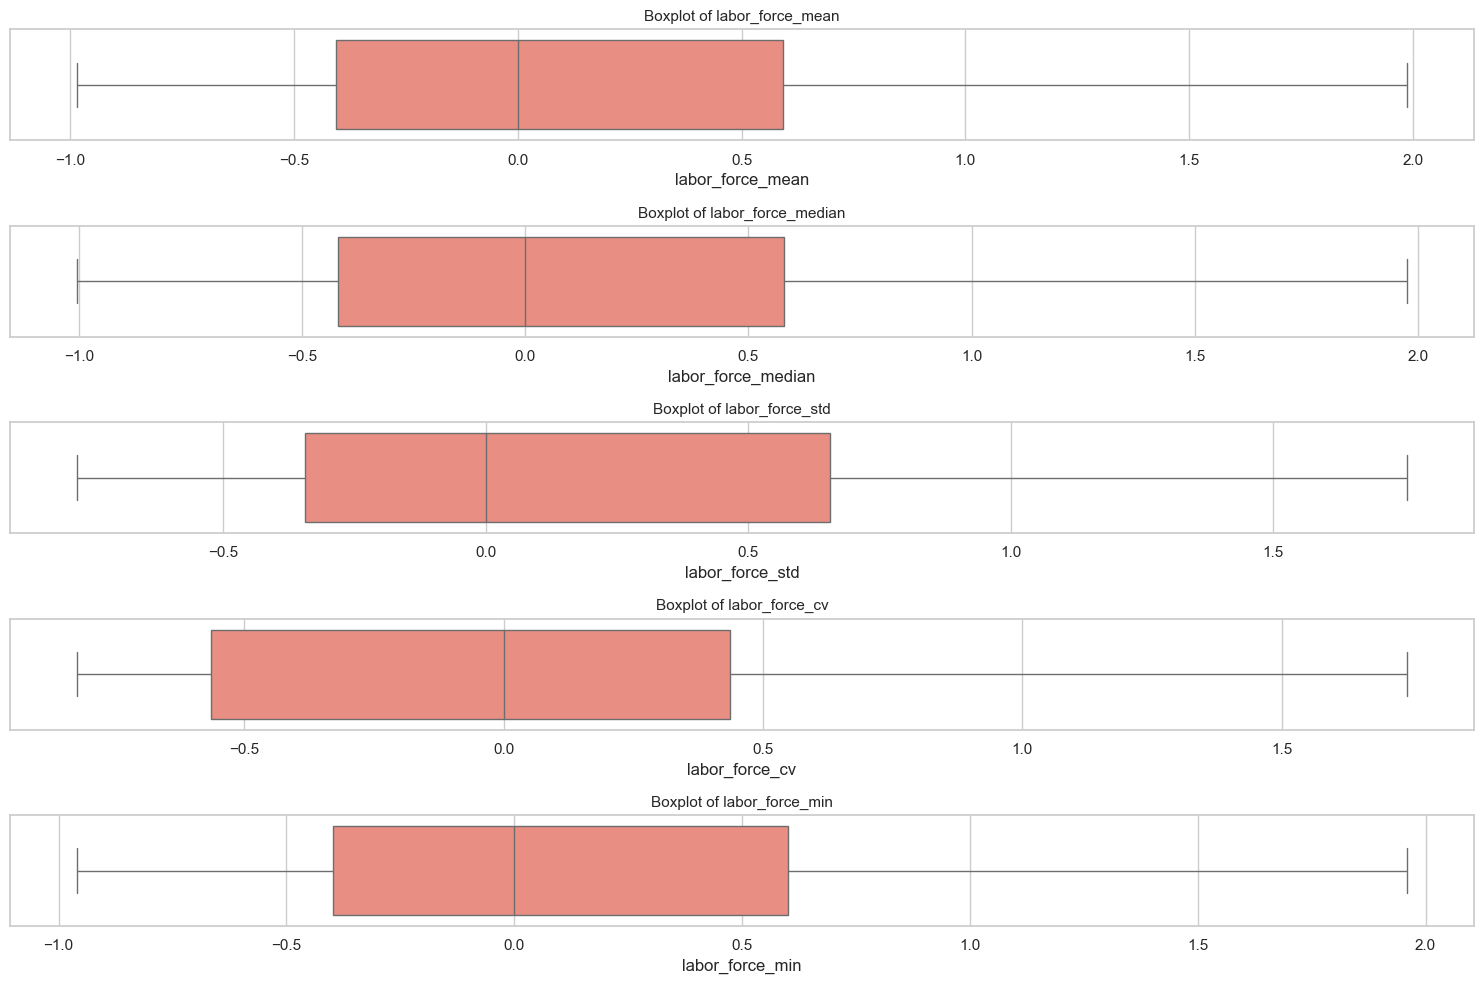

In [148]:
detect_top_outliers(scaled_winsorized)

In [149]:
scaled_winsorized.to_parquet("../data/log_win_robus_scaler_without_outliers_all_countries_ready_for_clust_and_pca.parquet")

In [150]:
percent_80_winsorized, final_limit, n_iters = adaptive_iterative_winsorize(without_80percent_countries_outliers)
print(f"Final winsorization limit: {final_limit}")
print(f"Iterations performed: {n_iters}")

Final winsorization limit: 0.19
Iterations performed: 8


In [151]:
percent_80_winsorized.to_parquet("../data/log_win_robust_scaler_80_less_outliers_ready_for_clust_and_pca_without_outliers.parquet")

In [152]:
percent_25_winsorized, final_limit, n_iters = adaptive_iterative_winsorize(without_25percent_countries_outliers)
print(f"Final winsorization limit: {final_limit}")
print(f"Iterations performed: {n_iters}")

Final winsorization limit: 0.19
Iterations performed: 8


In [153]:
percent_25_winsorized.to_parquet("../data/log_win_robust_scaler_25_less_outliers_ready_for_clust_and_pca_without_outliers.parquet")